# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB
frame_bytes = 1920 * 1080 * 3 * 1                 # W x H x C x B (8 bits = 1 byte)
frame_mb = frame_bytes / 1024**2

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 24 * 60 * 60                # f x T

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = frame_bytes * frames_per_day * 400 / 1024**4

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
small_frame_bytes = 640 * 360 * 3 * 1
small_frames_per_day = 10 * 24 * 60 * 60
fleet_tb_small = small_frame_bytes * small_frames_per_day * 400 / 1024**4
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")


One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_

**Spatial:** fine detail such as a licence-plate number, a face or the text on a badge. Going from 1080p to 360p keeps only 11.11% of the pixels, and raster interpolation (Slide 13) can only fill in smooth guesses between the surviving pixels, so the lost detail cannot be recovered later.

**Temporal:** a very short event or the exact order of events. At 10 fps there is a 100 ms gap between frames (instead of 33 ms), so a one-frame flash (like the lighting jump in this log) or the instant a person reaches a car can fall between frames. Larger gaps also make the correspondence problem (Slides 36-37) harder, because objects move so far between frames that it is unclear which object in one frame is which in the next.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

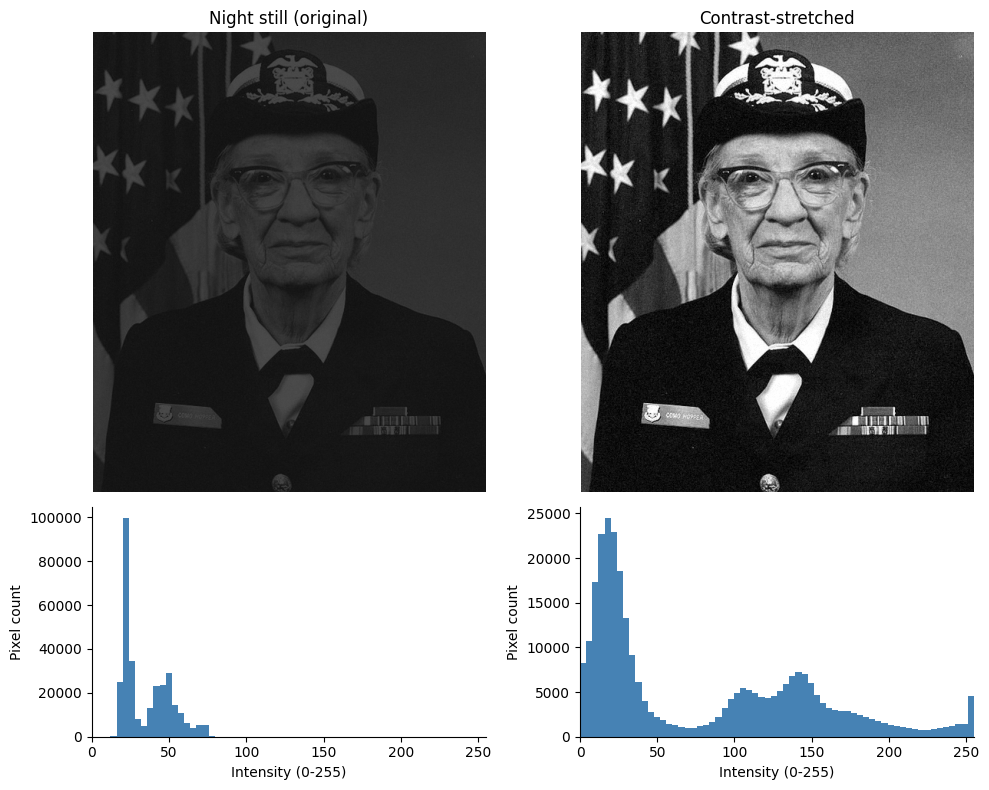

Contrast before: 0.609  ->  after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
lo, hi = np.percentile(night_still, [1, 99])
c_before = michelson(hi, lo)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - lo) / (hi - lo) * 255, 0, 255)

lo2, hi2 = np.percentile(stretched, [1, 99])
c_after = michelson(hi2, lo2)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
for col, (im, title) in enumerate([(night_still, "Night still (original)"),
                                   (stretched, "Contrast-stretched")]):
    axes[0, col].imshow(im, cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(title); axes[0, col].axis("off")
    axes[1, col].hist(im.ravel(), bins=64, range=(0, 255), color="steelblue")
    axes[1, col].set_xlim(0, 255)
    axes[1, col].set_xlabel("Intensity (0-255)"); axes[1, col].set_ylabel("Pixel count")

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")


**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_

The histogram is unimodal and narrow: almost all pixels sit in a small low-intensity range (roughly 18 to 80 out of 255) with a long thin tail towards the bright side, so in the Slide 18 vocabulary it is a dark (low-key), low-contrast image that uses only about a quarter of the available range. The stretch maps the 1st percentile to 0 and the 99th to 255, which spreads the same grey levels over the full range so neighbouring levels differ enough for the eye to see. It adds no new information because every pixel keeps its rank order (it is just a linear remapping, and it amplifies the noise along with the signal). A histogram alone cannot tell what is in the picture because it throws away all spatial arrangement: shuffling the pixels of the image gives a completely different picture with exactly the same histogram (Slide 18, "Same Histogram is not the Same Image"). Note also that Michelson contrast was already 0.61 before the stretch because the formula depends on the absolute offset (L_min is not zero), which is why the histogram width is the more honest diagnosis.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing: 68.7 s -> 78.1 s
Running: 78.6 s -> 86.0 s
Audio event:    frame 2250 (t = 75.0 s)
Lighting event: frame 3000 (t = 100.0 s)


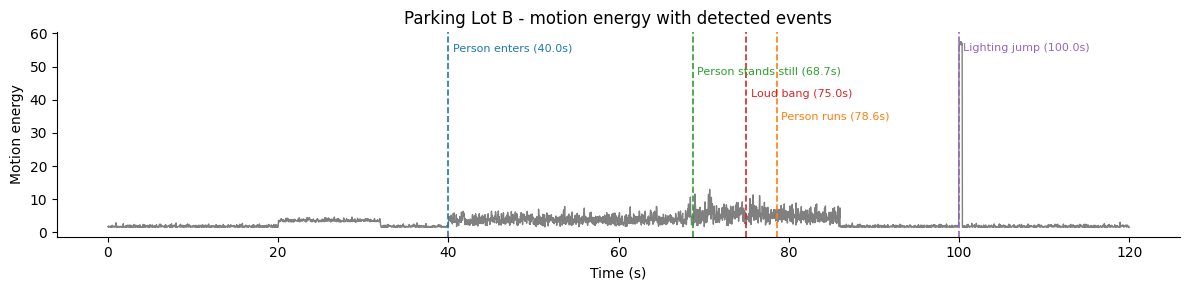

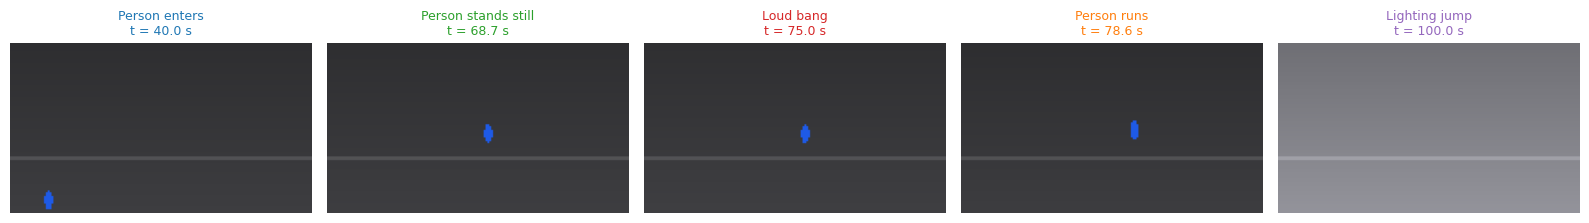

In [4]:
# TODO 1: person speed (px/s) -- displacement over a 1-second window (FPS frames)
dx = cctv.person_x.diff(FPS)
dy = cctv.person_y.diff(FPS)
speed = np.hypot(dx, dy)            # px per 1 s = px/s (NaN where the person is absent)
cctv["speed"] = speed
t = cctv.time_s

# TODO 2: standing / running time ranges (print the first and last time of each)
standing = speed < 3                # NaN < 3 is False, so absent frames are excluded
running = speed > 25
for name, mask in [("Standing", standing), ("Running", running)]:
    print(f"{name}: {t[mask].min():.1f} s -> {t[mask].max():.1f} s")

# TODO 3: event frame indices
audio_event_idx = int(np.argmax(cctv.audio_level_db.values > -20))                    # first frame above -20 dB
lighting_event_idx = int(np.argmax(cctv.mean_brightness.diff().abs().values > 40))    # first >40 jump in one frame
print(f"Audio event:    frame {audio_event_idx} (t = {t[audio_event_idx]:.1f} s)")
print(f"Lighting event: frame {lighting_event_idx} (t = {t[lighting_event_idx]:.1f} s)")

# Extra event markers for the timeline (first/last person frames, run start)
person_idx = int(cctv.person_x.first_valid_index())
run_idx = int(np.argmax(running.values))
events = [
    (person_idx, "Person enters", "tab:blue"),
    (int(np.argmax(standing.values)), "Person stands still", "tab:green"),
    (audio_event_idx, "Loud bang", "tab:red"),
    (run_idx, "Person runs", "tab:orange"),
    (lighting_event_idx, "Lighting jump", "tab:purple"),
]
events = sorted(events, key=lambda e: e[0])

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(t, cctv.motion_energy, color="gray", lw=1)
ymax = cctv.motion_energy.max()
for i, (idx, label, col) in enumerate(events):
    ax.axvline(t[idx], color=col, ls="--", lw=1.2)
    ax.text(t[idx] + 0.5, ymax * (0.95 - 0.12 * (i % 4)), f"{label} ({t[idx]:.1f}s)", color=col, fontsize=8)
ax.set_xlabel("Time (s)"); ax.set_ylabel("Motion energy"); ax.set_title("Parking Lot B - motion energy with detected events")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(1, len(events), figsize=(3.2 * len(events), 2.4))
for ax, (idx, label, col) in zip(axes, events):
    ax.imshow(render_frame(cctv.iloc[idx]))
    ax.set_title(f"{label}\nt = {t[idx]:.1f} s", fontsize=9, color=col)
    ax.axis("off")
plt.tight_layout(); plt.show()


**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_

The loud bang at 75.0 s (it lasts only about 2 s) and the moment the person starts running at 78.6 s would most likely be missed: uniform keyframes at 60 s and 80 s straddle them, so one shows a quiet scene and the other shows the person already running. The person entering (40 s) and the lighting jump (100 s) would only be caught if a keyframe happened to land exactly on them, which is luck. Slide 40 names the approach I used instead: content-based (event-driven) keyframe selection, where frames are chosen where the motion, audio or brightness signal changes, rather than at fixed time steps.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

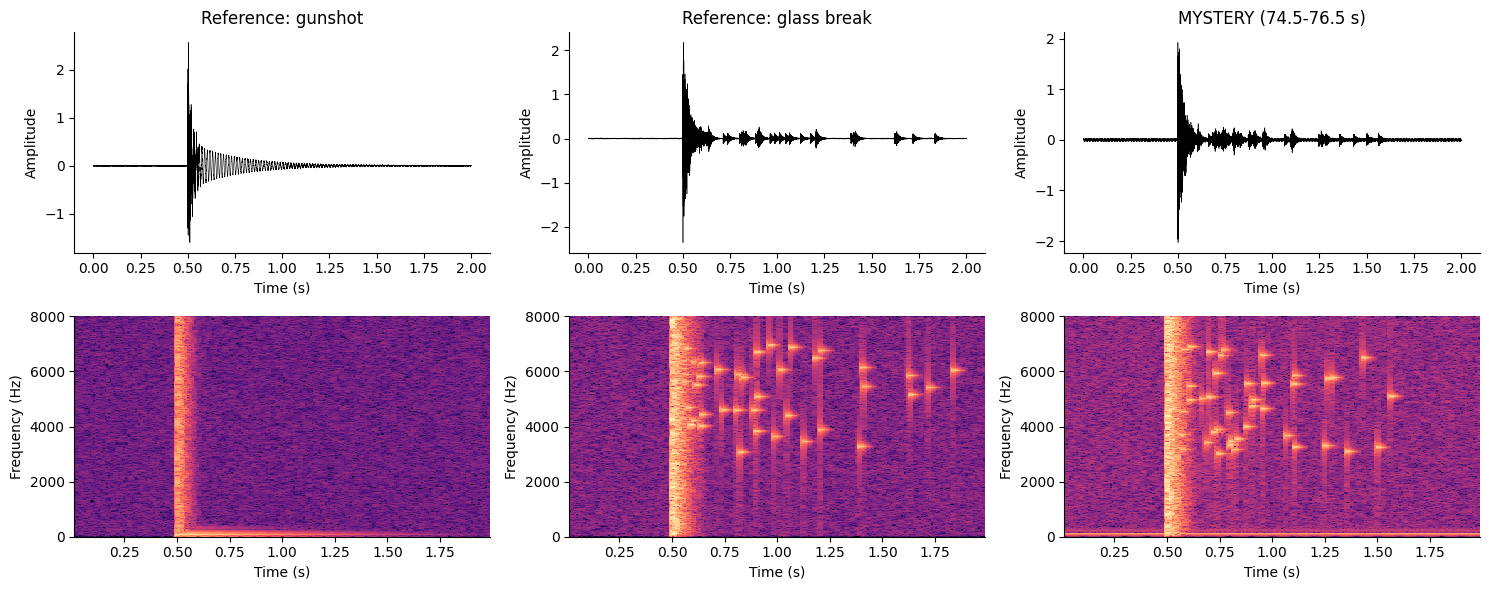

{'Reference: gunshot': 0.003, 'Reference: glass break': 0.989, 'MYSTERY (74.5-76.5 s)': 0.873}
Verdict: GLASS BREAKING - mystery HF fraction 0.87 vs glass 0.99 / gunshot 0.00; lingering high-frequency specks after the impact match the glass reference.


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
for col, (name, x) in enumerate(clips.items()):
    tt = np.arange(x.size) / FS
    axes[0, col].plot(tt, x, lw=0.4, color="k")
    axes[0, col].set_title(name); axes[0, col].set_xlabel("Time (s)"); axes[0, col].set_ylabel("Amplitude")
    f, ts, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    axes[1, col].pcolormesh(ts, f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma")
    axes[1, col].set_ylim(0, 8000)
    axes[1, col].set_xlabel("Time (s)"); axes[1, col].set_ylabel("Frequency (Hz)")

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, x in clips.items():
    f, ts, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    win = (ts >= 0.5 + 0.2) & (ts <= 0.5 + 1.2)
    band = Sxx[:, win]
    hf_fraction[name] = band[f > 3000].sum() / band.sum()

print({k: round(float(v), 3) for k, v in hf_fraction.items()})
# TODO 4: verdict
m = hf_fraction["MYSTERY (74.5-76.5 s)"]
g = hf_fraction["Reference: gunshot"]; gl = hf_fraction["Reference: glass break"]
verdict = "GLASS BREAKING" if abs(m - gl) < abs(m - g) else "GUNSHOT"
print(f"Verdict: {verdict} - mystery HF fraction {m:.2f} vs glass {gl:.2f} / gunshot {g:.2f}; "
      f"lingering high-frequency specks after the impact match the glass reference.")


**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_

No. In the waveforms the gunshot and the glass break both look like a sudden loud burst at 0.5 s followed by a decay, and the mystery clip looks the same, so amplitude against time cannot separate them confidently (the glass only has a slightly longer low-level tail). The spectrogram adds the frequency content: its three dimensions (Slide 57) are time on the x-axis, frequency on the y-axis and magnitude/energy shown as colour. The pattern that decided it was the scattered high-frequency specks (about 3-7 kHz) lingering after the impact. A gunshot gives a vertical stripe at the impact plus a low-frequency band and then silence, while the mystery clip showed the specks like the glass reference (about 87% of its energy above 3 kHz, against 99% for glass and 0.3% for the gunshot).

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

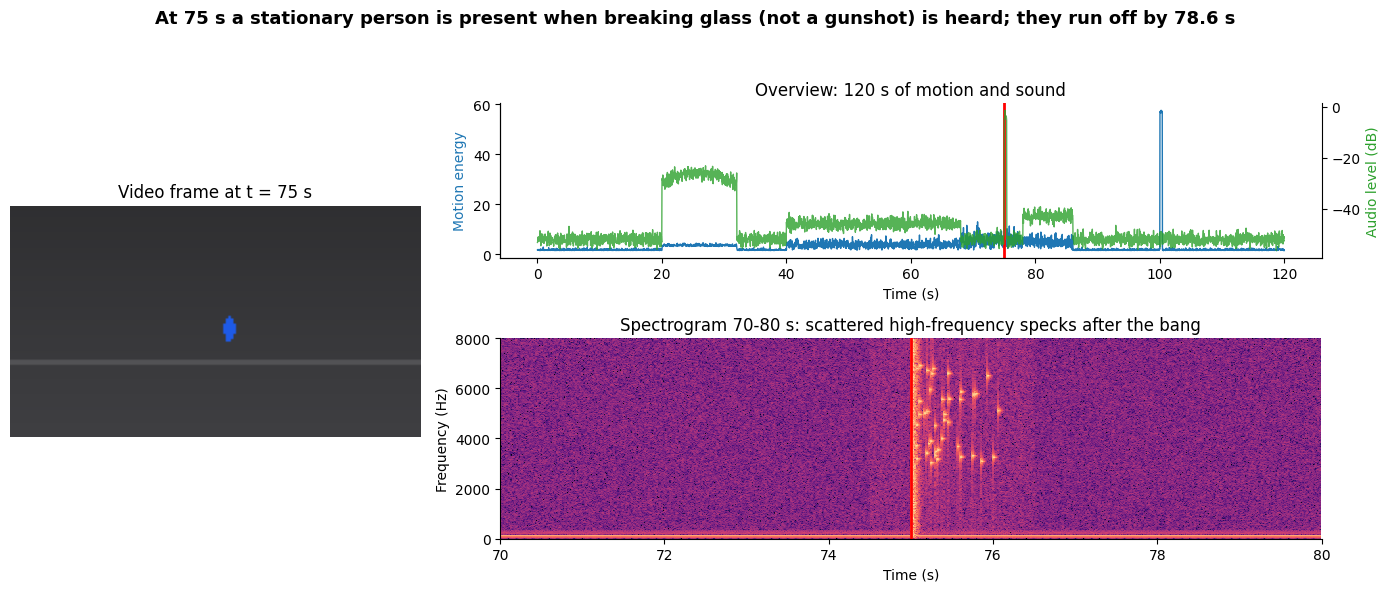

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4
# 1. video frame at t_sel (left, spans both rows)
ax_v = fig.add_subplot(gs[:, 0])
ax_v.imshow(render_frame(cctv.iloc[int(round(t_sel * FPS))]))
ax_v.set_title(f"Video frame at t = {t_sel:.0f} s"); ax_v.axis("off")

# 2. motion + audio timeline (top right)
ax_t = fig.add_subplot(gs[0, 1])
ax_t.plot(cctv.time_s, cctv.motion_energy, color="tab:blue", lw=1, label="Motion energy")
ax_t.set_ylabel("Motion energy", color="tab:blue"); ax_t.set_xlabel("Time (s)")
ax_a = ax_t.twinx()
ax_a.plot(cctv.time_s, cctv.audio_level_db, color="tab:green", lw=1, alpha=0.8, label="Audio level (dB)")
ax_a.set_ylabel("Audio level (dB)", color="tab:green")
ax_a.spines["right"].set_visible(True)
ax_t.axvline(t_sel, color="red", lw=2)
ax_t.set_title("Overview: 120 s of motion and sound")

# 3. spectrogram 70-80 s (bottom right)
ax_s = fig.add_subplot(gs[1, 1])
f, ts, Sxx = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
ax_s.pcolormesh(70 + ts, f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma")
ax_s.set_ylim(0, 8000); ax_s.set_xlim(70, 80)
ax_s.axvline(t_sel, color="red", lw=2)
ax_s.set_xlabel("Time (s)"); ax_s.set_ylabel("Frequency (Hz)")
ax_s.set_title("Spectrogram 70-80 s: scattered high-frequency specks after the bang")

# 4. conclusion-style title
fig.suptitle("At 75 s a stationary person is present when breaking glass (not a gunshot) is heard; "
             "they run off by 78.6 s", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()


**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_

The bang would appear 2 s later than it really happened, so the audio spike would line up with about 77 s instead of 75 s. At the 75 s marker the briefing would then show a person standing still in a silent scene, and the bang would appear to come just before the person starts running at 78.6 s. That would wrongly suggest the person fled almost immediately (about 1.6 s later instead of 3.6 s) and could change how the incident is interpreted. The mistake would be most visible in the spectrogram panel (and the audio line in the timeline), where the vertical stripe of the impact sits 2 s to the right of the red marker instead of on it. This is also why the common time reference (Slide 59) matters: a wrong sync is silently misleading, and too many panels at once (Slide 61) make it harder to spot.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_

At 75.0 s in Lot B a person who had been standing still since about 68.7 s was present when a loud bang occurred, the spectrogram shows it was breaking glass (about 87% of its energy above 3 kHz, like the glass reference) and not a gunshot, and the person then ran from 78.6 s to 86.0 s, followed by a lighting jump at 100.0 s. I would show the synchronized view first, because it links video, motion and audio on one time axis (overview first, then detail at the selected moment) and lets the Head of Security check the structure, pattern, change, event and meaning chain at one timestamp; the spectrogram (time x frequency x magnitude) is what justifies "glass, not gunshot". For storage, storing everything uncompressed in 1080p at 30 fps would be about 5,866 TB per day for 400 cameras, so I recommend a 360p/10 fps baseline (about 217 TB per day) with full-quality recording triggered around detected events. The one piece of evidence the policy must not sacrifice is the audio (kept at a sampling rate like 16 kHz, because the glass-versus-gunshot decision depends on content above 3 kHz), together with full frame rate around events.